# CARE ML1: CatBoost on the 15-minute grid and NVIDIA Kumo Tabular, against the baseline and the LSTM

**Question (ML1).** Will this turbine be inside, or enter, an anomaly window within the next 7 days? Same target, folds,
labels, threshold rule and checks as the CatBoost baseline (`notebooks/care_catboost_baseline.md`, branch
`feature/catboost_failure-baseline`).

**What is new here.**
- **CatBoost 15 min**: the anchors of the BiLSTM (`fault_detection/care_fault_forecast.py`: 15-minute time-weighted bins,
  48 h lookback, stride 1 for anchors with an onset within 7 days, stride 4 otherwise, anchors from the onset on dropped),
  window statistics instead of a sequence model, a censored "onset within 7 days" target. One model per farm.
- **Feature selection with SHAP**, filtered for position in the timeline, season, `status_type_id` and class overlap.
- **Kumo Tabular** (NVIDIA, in-context tabular model, large size) on the shortlist, same folds, on a Kaggle 2x T4.

**This notebook trains nothing.** It reads the outputs of `fault_detection/care_catboost_15min.py` (`features`, `cv`,
`select`, `kumo-eval`, `timing`, `report`) and of the Kaggle kernel built by `fault_detection/build_kumo_kernel.py`, from
`dataset/wind_turbine_scada_fault/cache/catboost_15min/`. The commands are in section 7.

Every number here is measured unless it says "estimated".

In [1]:
import io, json, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from PIL import Image as PILImage

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 48)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit
ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache" / "catboost_15min"
FARMS = ["A", "B", "C"]

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#a9a8a2", "#e4e3de"
MODEL_COLORS = {"season only": MUTED, "CatBoost daily (baseline)": "#2a78d6", "LSTM-attention (all channels)": "#eb6834",
                "CatBoost 15 min": "#1baf7a", "CatBoost 15 min shortlist": "#eda100", "Kumo Tabular (shortlist)": "#e87ba4"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})


def show(fig, name, dpi=80, colors=96):
    """Full-resolution PNG to the cache, a small palette PNG inline (repo limit 500 KB per file)."""
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight"); plt.close(fig)
    im = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    small = io.BytesIO(); im.save(small, format="PNG", optimize=True)
    display(IPImage(small.getvalue()))

## 1. Setup and the checks done before modelling

- **Folds**: `catboost_baseline/cv_folds.parquet`, scheme `per_farm` (A and B leave one turbine out, 5 and 9 folds; C 5 folds
  dealt by event count), seeds 0, 1, 2. The LSTM's `fold_split` (5 folds over all farms, seed 42) is **not** the same
  partition (it left farm A without a test turbine in one fold), and the cached LSTM results were run on `cv_folds.parquet`
  too, so the baseline's folds were used for every model here (the owner's choice).
- **Variant fix**: `care_fault_forecast.prepare` read `comma_event_info.csv` but the `;` CSVs. Event ids and sensor values
  are identical in both variants, timestamps are not, and the daily join needs the comma timestamps; `dataset_path` now
  prefers the comma CSV.
- **Timeline fix**: `make_anchors` sees one dataset at a time. In 5 timelines (A 2, B 1, C 2) another dataset's onset
  lies in this dataset's train part on identical rows, so the same 15-minute window was labelled "fails" in one dataset
  and "does not fail" in the other. After `make_anchors` (unchanged), training anchors inside [onset, end + 14 days] of
  any event of their timeline are dropped and an onset of another dataset within 7 days sets the target
  (`segment_targets`). Remaining disagreements with the daily labels are day-boundary cases (at most 18 anchors per dataset).
- **Daily score** = maximum of the day's 15-minute scores over stride-4 anchors only (positives are sampled at stride 1;
  a maximum over 4 times more draws would favour positive days). Every labelled baseline day gets a score (A 4,322 of
  4,322, B 3,208 of 3,209, C 12,289 of 12,289).
- **Features** per channel over the 48 h window: last, mean, std, min, max, OLS slope (per hour), mean of the last 6 h
  minus the 42 h before; the missing flag gives its last value and window mean. A 352, B 464, C 1,752 features.
  `status_type_id` is never read.

In [2]:
print((OUT / "features.log").read_text())

farm A: 204,974 anchors (200,052 train, 7,728 with an onset within 7 d; timeline fix: {'dropped': 1597, 'relabelled': 336}), 352 features, 0.29 GB, 3s
farm B: 145,597 anchors (138,301 train, 4,200 with an onset within 7 d; timeline fix: {'dropped': 1080, 'relabelled': 168}), 464 features, 0.27 GB, 3s
farm C: 542,187 anchors (528,732 train, 17,808 with an onset within 7 d; timeline fix: {'dropped': 1288, 'relabelled': 336}), 1752 features, 3.80 GB, 25s



## 2. Run time (measured on the MacBook M5 CPU, 10 threads)

The owner's unmeasured guess was 15 to 25 h for all features and 7 horizons. Measured: one fold of farm A at k = 7 takes
6 s, one fold of farm C 90 s (415,829 rows x 1,752 features, 8 GB resident). Early stopping ends at 30 to 45 trees, so
the whole k = 7 run with 3 seeds took about 25 minutes, and 6 more horizons with one seed about an hour.

In [3]:
runs = {f: pd.read_pickle(OUT / "runs" / f"cb15_{f}_k7.pkl") for f in FARMS}
info = pd.concat([r["info"].assign(farm=f) for f, r in runs.items()])
display(info.groupby("farm").agg(folds=("fold", "size"), fit_rows=("n_fit", "median"), positives=("n_pos", "median"),
                                 features=("n_features", "first"), trees=("n_trees", "median"),
                                 seconds_per_fold=("seconds_total", "median"), minutes_total=("seconds_total", lambda s: s.sum() / 60)).round(1))

      folds  fit_rows  positives  features  trees  seconds_per_fold  minutes_total
farm                                                                              
A        15  161836.0     6216.0       352   30.0               5.2            1.3
B        27  118704.0     3528.0       464   30.0               4.7            2.1
C        15  416178.0    14280.0      1752   39.0              80.9           19.6

## 3. Headline: ROC-AUC and recall at k = 7 (out of fold)

Same table as the baseline (section 3 there). Event recall is read at the threshold chosen on the training turbines (at
most 1 false alarm per turbine-month); the false alarms are what that threshold produced on the **test** turbines.
95% intervals: cluster bootstrap over turbines, 1000 resamples. Two targets:
- **main**: inside or entering an anomaly window within 7 days (the baseline's target);
- **strict**: only the days before onset (days inside a window left out). The 15-minute models are trained for this one
  (anchors from the onset on are dropped), so it is their own task.

In [4]:
H = pd.read_csv(OUT / "results_headline.csv")
H = H[H["model"] != "LSTM q672 centred"]
for tgt, g in H.groupby("target", sort=False):
    print("==", tgt)
    display(g.drop(columns=["target"]).set_index(["farm", "model"]))

== main: inside or entering within 7 d


                                   ROC-AUC pooled [95% CI] ROC-AUC within turbine [95% CI] event recall [95% CI]  false alarms / turbine-month  PR-AUC  prevalence  days scored  events
farm model                                                                                                                                                                             
A    season only                      0.645 [0.473, 0.883]            0.673 [0.518, 0.876]     0.91 [0.70, 1.00]                          3.21   0.104       0.047         4322      11
     CatBoost daily (baseline)        0.658 [0.604, 0.756]            0.695 [0.639, 0.767]     0.73 [0.60, 0.90]                          0.91   0.127       0.047         4322      11
     LSTM-attention (all channels)    0.596 [0.509, 0.771]            0.616 [0.517, 0.765]     0.64 [0.38, 0.82]                          0.75   0.087       0.047         4322      11
     LSTM q672 residual               0.572 [0.481, 0.750]            0.601 [0.5

== strict: onset within 7 d


                                   ROC-AUC pooled [95% CI] ROC-AUC within turbine [95% CI] event recall [95% CI]  false alarms / turbine-month  PR-AUC  prevalence  days scored  events
farm model                                                                                                                                                                             
A    season only                      0.679 [0.595, 0.868]            0.730 [0.632, 0.860]     0.91 [0.70, 1.00]                          3.21   0.062       0.018         4196      11
     CatBoost daily (baseline)        0.717 [0.585, 0.814]            0.693 [0.575, 0.804]     0.73 [0.60, 0.90]                          0.91   0.087       0.018         4196      11
     LSTM-attention (all channels)    0.629 [0.475, 0.786]            0.635 [0.505, 0.787]     0.64 [0.38, 0.82]                          0.75   0.040       0.018         4196      11
     LSTM q672 residual               0.617 [0.450, 0.796]            0.628 [0.5

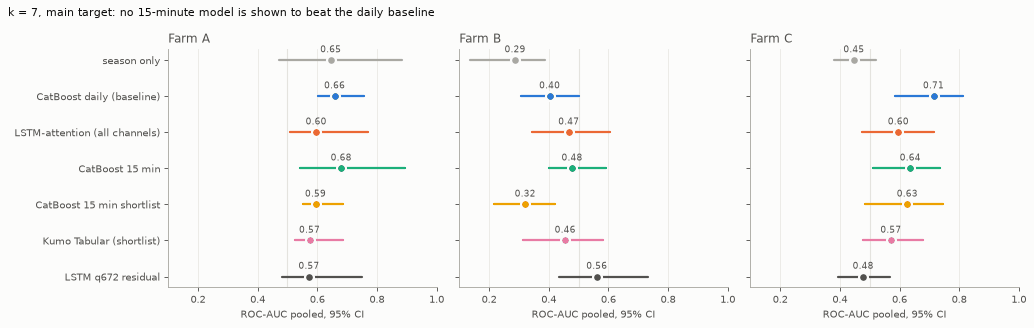

In [5]:
def lohi(s):
    v, ci = s.split(" [")
    lo, hi = ci.rstrip("]").split(", ")
    return float(v), float(lo), float(hi)

main = H[H["target"].str.startswith("main")]
order = [m for m in MODEL_COLORS if m in set(main["model"])] + [m for m in main["model"].unique() if m not in MODEL_COLORS]
fig, axes = plt.subplots(1, 3, figsize=(13, 0.42 * len(order) + 1.2), sharey=True)
for ax, f in zip(axes, FARMS):
    g = main[main["farm"] == f].set_index("model")
    for i, m in enumerate(order):
        if m not in g.index:
            continue
        v, lo, hi = lohi(g.loc[m, "ROC-AUC pooled [95% CI]"])
        c = MODEL_COLORS.get(m, INK2)
        ax.plot([lo, hi], [i, i], color=c, lw=2, solid_capstyle="round")
        ax.plot(v, i, "o", ms=8, color=c, mec=SURFACE, mew=2)
        ax.annotate(f"{v:.2f}", (v, i), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.axvline(0.5, color=GRID, lw=1, zorder=0)
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlim(0.1, 1.0); ax.set_xlabel("ROC-AUC pooled, 95% CI")
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order); axes[0].invert_yaxis()
fig.suptitle("k = 7, main target: no 15-minute model is shown to beat the daily baseline", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
show(fig, "headline_auc")

## 4. The baseline's checks

Paired cluster bootstrap over turbines (the same resampled turbines for both models) of the ROC-AUC difference against
the season-only model and against the daily CatBoost baseline, pooled and within turbine; the **same-position test**
(anomaly against normal datasets in the days 7 before to 14 after each dataset's own window start: dataset AUC of the
maximum score, one-sided permutation p, 5000 shuffles) and its pre-onset version (the 7 days before the window start).

In [6]:
C = pd.read_csv(OUT / "results_checks.csv")
C = C[C["model"] != "LSTM q672 centred"]
for tgt, g in C.groupby("target", sort=False):
    print("==", tgt)
    display(g.drop(columns=["target"]).dropna(axis=1, how="all").set_index(["farm", "model"]))

== main: inside or entering within 7 d


                                    ROC-AUC  vs season only [95% CI] beats season? vs CatBoost daily [95% CI] beats baseline? vs CatBoost daily, within turbine [95% CI] beats baseline within?  \
farm model                                                                                                                                                                                        
A    CatBoost daily (baseline)        0.658  +0.014 [-0.141, +0.166]     not shown    +0.000 [+0.000, +0.000]       not shown                    +0.000 [+0.000, +0.000]              not shown   
     LSTM-attention (all channels)    0.596  -0.048 [-0.208, +0.077]     not shown    -0.062 [-0.123, +0.026]       not shown                    -0.079 [-0.130, +0.011]              not shown   
     LSTM q672 residual               0.572  -0.072 [-0.291, +0.054]     not shown    -0.086 [-0.197, +0.037]       not shown                    -0.094 [-0.173, +0.009]              not shown   
     CatBoost 15 min     

== strict: onset within 7 d


                                    ROC-AUC  vs season only [95% CI] beats season? vs CatBoost daily [95% CI] beats baseline? vs CatBoost daily, within turbine [95% CI] beats baseline within?
farm model                                                                                                                                                                                     
A    CatBoost daily (baseline)        0.717  +0.037 [-0.159, +0.144]     not shown    +0.000 [+0.000, +0.000]       not shown                    +0.000 [+0.000, +0.000]              not shown
     LSTM-attention (all channels)    0.629  -0.050 [-0.218, +0.067]     not shown    -0.088 [-0.144, +0.015]       not shown                    -0.058 [-0.107, +0.003]              not shown
     LSTM q672 residual               0.617  -0.062 [-0.296, +0.070]     not shown    -0.100 [-0.156, +0.008]       not shown                    -0.065 [-0.092, -0.017]              no, worse
     CatBoost 15 min                  0.

## 5. Feature selection: SHAP stability and the filters

- **SHAP**: mean |SHAP| of the final model of every fold on 3,000 stride-4 anchors of that fold's **test** turbines (seed 0).
  A feature is **stable** when it is in the top 150 of the fold in at least 80% of the folds (4 of 5 in A and C, 8 of 9
  in B).
- **Filters**, on the stride-4 training anchors (positives thinned to stride 4 like the negatives):
  - `status_type_id`: never an input (asserted on the feature list);
  - **position**: normal datasets only, the 14 days around the end of the train part (where positives sit in anomaly
    datasets) against days 300 to 60 before it; |AUC - 0.5| >= 0.15 means the feature reads the dataset geometry;
  - **season**: label AUC before and after removing a two-harmonic day-of-year curve fitted on negatives; flagged when the
    season explains more than half of the distance from 0.5 (and that distance is at least 0.05);
  - **overlap**: overlap coefficient of the "fails" and "does not fail" distributions; >= 0.98 means indistinguishable.
- **Shortlist**: stable and not flagged, by mean |SHAP|, at most 100 (Kumo Tabular was trained on tables of up to 100
  columns).
- **Caveat**: the shortlist is chosen once per farm from all folds, and the season and overlap filters use labels, so the
  shortlist runs are slightly optimistic (selection information crosses folds). They still do not beat the full model.

In [7]:
for f in FARMS:
    s = pd.read_csv(OUT / f"screen_{f}.csv", index_col=0)
    st = s[s["stable"]]
    print(f"farm {f}: {len(s)} features, stable {len(st)}, flagged among stable: position {int(st['flag_position'].sum())}, "
          f"season {int(st['flag_season'].sum())}, overlap {int(st['flag_overlap'].sum())}; shortlist {int(s['shortlist'].sum())}")
    cols = ["mean_abs_shap", "folds_in_top", "label_auc", "season_adj_auc", "position_auc", "overlap"]
    print("  top of the shortlist:"); display(s[s["shortlist"]][cols].head(10).round(3))
    print("  stable but removed:"); display(st[~st["kept"]][cols + ["flag_position", "flag_season"]].head(8).round(3))

farm A: 352 features, stable 124, flagged among stable: position 1, season 27, overlap 0; shortlist 96
  top of the shortlist:


                        mean_abs_shap  folds_in_top  label_auc  season_adj_auc  position_auc  overlap
feature                                                                                              
sensor_38_avg__min              0.047             5      0.635           0.600         0.560    0.619
sensor_26_avg__mean             0.032             5      0.376           0.352         0.423    0.618
sensor_42_avg_sin__max          0.031             4      0.487           0.422         0.540    0.521
sensor_2_avg_cos__max           0.027             5      0.442           0.429         0.505    0.589
sensor_2_avg_cos__last          0.023             5      0.584           0.602         0.603    0.774
sensor_22_avg__max              0.022             4      0.626           0.637         0.517    0.528
sensor_1_avg_sin__max           0.022             5      0.469           0.403         0.509    0.491
sensor_26_avg__min              0.020             4      0.432           0.367    

  stable but removed:


                        mean_abs_shap  folds_in_top  label_auc  season_adj_auc  position_auc  overlap  flag_position  flag_season
feature                                                                                                                          
sensor_0_avg__min               0.046             5      0.693           0.542         0.541    0.457          False         True
sensor_43_avg__min              0.044             5      0.663           0.511         0.572    0.515          False         True
sensor_6_avg__min               0.034             5      0.674           0.543         0.559    0.541          False         True
sensor_6_avg__max               0.033             5      0.700           0.577         0.545    0.512          False         True
sensor_0_avg__mean              0.031             5      0.684           0.567         0.532    0.562          False         True
sensor_2_avg_cos__mean          0.023             5      0.495           0.514         0.6

farm B: 464 features, stable 119, flagged among stable: position 19, season 16, overlap 0; shortlist 89
  top of the shortlist:


                        mean_abs_shap  folds_in_top  label_auc  season_adj_auc  position_auc  overlap
feature                                                                                              
sensor_15_avg__max              0.044             8      0.297           0.305         0.390    0.480
sensor_10_avg_sin__min          0.042             9      0.489           0.544         0.493    0.445
sensor_1_avg_diff__min          0.041             9      0.551           0.573         0.500    0.582
sensor_4_avg_sin__max           0.030             9      0.652           0.647         0.486    0.467
sensor_9_avg__last              0.029             9      0.536           0.483         0.449    0.353
sensor_33_avg__max              0.026             9      0.491           0.493         0.569    0.497
sensor_0_avg_diff__min          0.025             9      0.525           0.514         0.500    0.445
sensor_4_avg_cos__min           0.021             9      0.485           0.477    

... (2 outputs left out)

farm C: 1752 features, stable 70, flagged among stable: position 0, season 0, overlap 0; shortlist 70
  top of the shortlist:


                      mean_abs_shap  folds_in_top  label_auc  season_adj_auc  position_auc  overlap
feature                                                                                            
sensor_225_avg__mean          0.061             5      0.605           0.603         0.597    0.544
sensor_225_avg__min           0.027             5      0.583           0.588         0.583    0.583
sensor_27_avg__min            0.027             4      0.480           0.449         0.506    0.643
sensor_227_avg__min           0.022             4      0.478           0.498         0.496    0.758
sensor_225_avg__last          0.022             4      0.612           0.610         0.596    0.562
sensor_109_avg__min           0.019             4      0.601           0.617         0.574    0.572
sensor_225_avg__max           0.016             5      0.597           0.597         0.574    0.567
sensor_81_avg__max            0.014             5      0.398           0.413         0.424    0.644


  stable but removed:


Empty DataFrame
Columns: [mean_abs_shap, folds_in_top, label_auc, season_adj_auc, position_auc, overlap, flag_position, flag_season]
Index: []

**Class overlap, one panel per feature** (top 6 of each farm's shortlist): distribution on "fails within 7 days" against
"does not fail" anchors. Overlap coefficients of 0.4 to 0.6 look separable, but positives come from only 11 / 6 / 27
events, so each class's histogram is a few turbines and weeks: the low overlap is mostly *which week*, not a fault
signature, which is why the out-of-fold AUCs above stay near the baseline.

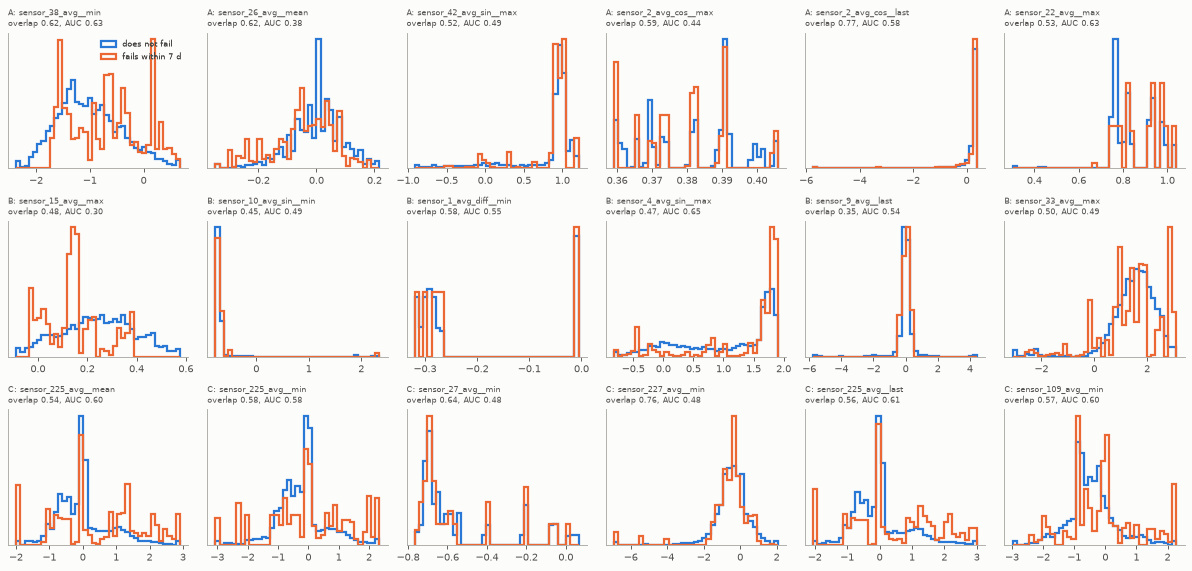

In [8]:
import sys
sys.path.insert(0, str(ROOT / "fault_detection"))
from care_catboost_15min import target

fig, axes = plt.subplots(3, 6, figsize=(15, 7.2))
for r, f in enumerate(FARMS):
    s = pd.read_csv(OUT / f"screen_{f}.csv", index_col=0)
    top = s[s["shortlist"]].index[:6]
    A = pd.read_parquet(OUT / f"anchors_{f}.parquet", columns=["k", "c", "train", "eval"])
    X = np.load(OUT / f"X_{f}.npy", mmap_mode="r")
    names = json.loads((OUT / f"features_{f}.json").read_text())
    y = target(A, 7)
    rows = np.flatnonzero(A["train"].to_numpy() & A["eval"].to_numpy() & np.isfinite(y))
    for c, feat in enumerate(top):
        ax = axes[r, c]
        v = np.asarray(X[rows, names.index(feat)], float)
        lo, hi = np.nanpercentile(v, [0.5, 99.5])
        bins = np.linspace(lo, hi, 40)
        for cls, col, lab in ((0, "#2a78d6", "does not fail"), (1, "#eb6834", "fails within 7 d")):
            ax.hist(np.clip(v[y[rows] == cls], lo, hi), bins=bins, density=True, histtype="step", lw=2, color=col, label=lab)
        ax.set_title(f"{f}: {feat}\noverlap {s.loc[feat, 'overlap']:.2f}, AUC {s.loc[feat, 'label_auc']:.2f}", fontsize=7.5, loc="left", color=INK2)
        ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout()
show(fig, "overlap_top_features")

## 6. Kumo Tabular

**Documentation checked first** (docs.nvidia.com/sdgm, the Hugging Face model card and blog, the `structured-data-models`
API reference): no hard inference limit on rows or columns is documented. The model was trained on tables of up to
60,000 rows and 100 columns, and NVIDIA warns that accuracy may degrade far outside those ranges; the default recipe
caps columns at 500 (`SelectColumns(max_columns=500)`), at most 10 classes per pass. Inputs must be numerical. Hence: the
shortlist (at most 100 columns) and a context of 10,240 rows (the largest size of the second training stage), positives
up to 25% of it.

**Where it ran.** Not on the MacBook (no CUDA): a private Kaggle kernel (`teodorapanait/care-kumo-tabular-15min`,
2x Tesla T4), which attaches the public CARE dataset and rebuilds the 15-minute arrays and features with the same code
(it reproduced the local anchor counts exactly: A 204,974, B 145,597, C 542,187). Farm C on one GPU, A then B on the other.

**Measured speed** (smoke test, farm A fold 0, large, 4 estimators): fit 19 s, 45,382 queries in 236 s (192 rows per
second). The full run with 4 estimators was estimated at about 10 GPU hours, so the owner chose **1 estimator**.
Per outer fold: 3 inner fits (context from the other inner groups, query the held-out one, for the threshold and the
isotonic calibration) and the final fit (context from all training turbines, query the test turbines). Seed 0 folds only
(the baseline uses 3 seeds; in A and B the folds are identical across seeds, in C they differ).

**Importance** by permutation (not KernelSHAP): on 1,000 labelled test anchors per fold, the drop of the anchor-level
ROC-AUC when one column is shuffled.

In [9]:
KUMO = OUT / "kumo_full" / "kumo"
tim = pd.concat([pd.read_csv(p) for p in sorted(KUMO.glob("kumo_*_timing.csv"))]) if KUMO.exists() else pd.DataFrame()
if len(tim):
    tim["rows_per_s"] = tim["queries"] / tim["seconds_predict"]
    display(tim.groupby(["farm", "stage"]).agg(fits=("fold", "size"), context=("context", "median"), queries=("queries", "sum"),
                                               fit_s=("seconds_fit", "sum"), predict_min=("seconds_predict", lambda s: s.sum() / 60),
                                               rows_per_s=("rows_per_s", "median")).round(1))
else:
    print("no Kumo results in", KUMO)

            fits  context  queries  fit_s  predict_min  rows_per_s
farm stage                                                        
A    final     5  10240.0   199430   17.9          3.9       838.7
     inner    15  10240.0   797720   56.0         15.5       839.9
B    final     9  10240.0   142573   30.9          2.8       854.3
     inner    27  10240.0  1140584   92.3         22.3       850.6
C    final     5  10240.0   528579   16.5         10.9       805.3
     inner    15  10240.0  2114316   50.8         43.9       802.7

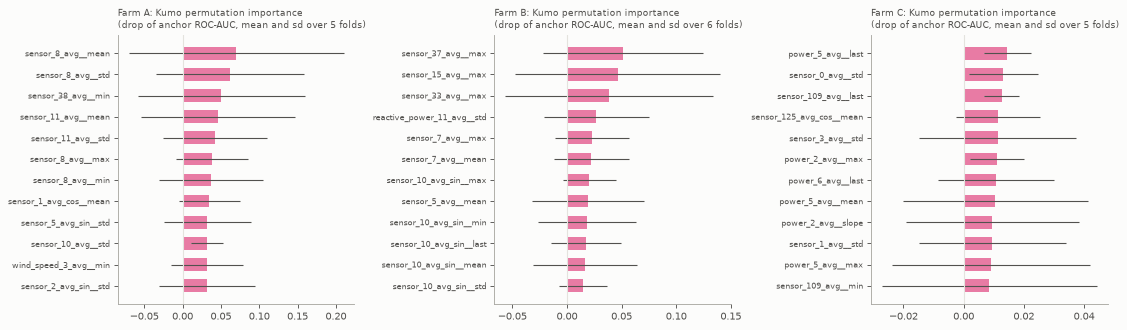

      count   mean    min    max
farm                            
A     480.0  0.725  0.614  0.830
B     534.0  0.548  0.117  0.797
C     350.0  0.614  0.520  0.841

In [10]:
perm = pd.concat([pd.read_csv(p) for p in sorted(KUMO.glob("kumo_*_perm.csv"))]) if KUMO.exists() and list(KUMO.glob("kumo_*_perm.csv")) else None
if perm is not None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, f in zip(axes, FARMS):
        p = perm[perm["farm"] == f]
        if p.empty:
            continue
        g = p.groupby("feature")["auc_drop"].agg(["mean", "std", "count"]).sort_values("mean", ascending=False).head(12)[::-1]
        ax.barh(range(len(g)), g["mean"], color="#e87ba4", height=0.6)
        ax.errorbar(g["mean"], range(len(g)), xerr=g["std"], fmt="none", ecolor=INK2, lw=1)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=7)
        ax.axvline(0, color=GRID, lw=1)
        ax.set_title(f"Farm {f}: Kumo permutation importance\n(drop of anchor ROC-AUC, mean and sd over {p['fold'].nunique()} folds)",
                     loc="left", fontsize=8.5, color=INK2)
    fig.tight_layout()
    show(fig, "kumo_permutation_importance")
    display(perm.groupby("farm")["base_auc"].describe()[["count", "mean", "min", "max"]].round(3))

## 7. Timing error (k = 1..7 horizon models)

The LSTM session's protocol: test anchors 1 to 7 days before an onset that has a logged time (Farm B and about half of C
log onsets at 00:00, day resolution only), the cumulative risks of the seven horizon models made monotone, the
conditional distribution over the week spread uniformly inside each day, its median against the true onset bin. The
reference is a uniform curve over the week. The LSTM rows come from the LSTM session (daily anchors), so the anchor sets
differ; compare each model with its own uniform reference.

In [11]:
T = OUT / "results_timing.csv"
display(pd.read_csv(T).set_index(["farm", "model"])) if T.exists() else print("no timing results")

                                       anchors  events  median |error| (h)  uniform curve: median |error| (h)  true onset day = predicted median day  80% interval coverage  80% interval width (h)  \
farm model                                                                                                                                                                                            
A    CatBoost 15 min (k=1..7, seed 0)     1440    10.0               32.75                              36.00                                   0.21                   0.77                  106.25   
B    CatBoost 15 min (k=1..7, seed 0)      144     1.0               41.12                              36.00                                   0.21                   0.75                  112.75   
C    CatBoost 15 min (k=1..7, seed 0)     2160    15.0               35.25                              36.00                                   0.17                   0.75                  116.00   
A    

## 8. Commands (conda env `ml_def`)

```
python fault_detection/care_fault_forecast.py prepare --input dataset/wind_turbine_scada_fault/raw --out dataset/wind_turbine_scada_fault/cache/catboost_15min/prepared --stats avg --workers 4
python fault_detection/care_catboost_15min.py features --farms A,B,C
python fault_detection/care_catboost_15min.py cv --farm A --horizon 7 --seeds 0,1,2 --name cb15 --save-anchor-scores
python fault_detection/care_catboost_15min.py select --farms A,B,C
python fault_detection/care_catboost_15min.py cv --farm A --horizon 7 --seeds 0,1,2 --name cb15short --features dataset/wind_turbine_scada_fault/cache/catboost_15min/shortlist.json --no-shap
python fault_detection/build_kumo_kernel.py --mode full
kaggle kernels push -p fault_detection/kaggle_kumo --accelerator NvidiaTeslaT4
python fault_detection/care_catboost_15min.py kumo-eval --kumo dataset/wind_turbine_scada_fault/cache/catboost_15min/kumo_full/kumo
python fault_detection/care_catboost_15min.py cv --farm A --horizon 1 --seeds 0 --name cb15 --save-anchor-scores --no-shap
python fault_detection/care_catboost_15min.py timing
python fault_detection/care_catboost_15min.py report --models "CatBoost 15 min=cb15,CatBoost 15 min shortlist=cb15short,Kumo Tabular (shortlist)=kumo"
```
(`cv` once per farm, and per horizon 1 to 6 for the timing.)

## 9. Conclusions

1. **No new model beats the daily CatBoost baseline in any farm.** Pooled ROC-AUC, main target, k = 7:

   | farm | season only | CatBoost daily | LSTM-attention | CatBoost 15 min | CatBoost 15 min shortlist | Kumo Tabular |
   |---|---|---|---|---|---|---|
   | A | 0.645 | 0.658 | 0.596 | 0.680 | 0.594 | 0.574 |
   | B | 0.287 | 0.403 | 0.467 | 0.478 | 0.321 | 0.455 |
   | C | 0.447 | **0.714** | 0.596 | 0.636 | 0.626 | 0.571 |

   No difference against the baseline has an interval above zero. Kumo is worse than the baseline in C
   (-0.143 [-0.273, -0.011]); the CatBoost shortlist is worse in A and B.
2. **CatBoost 15 min** is the best of the new models: its point estimate is above the baseline in A (0.680 against 0.658,
   +0.022 [-0.095, +0.149]) and B, but it does not beat season only in A, its threshold breaks the false-alarm budget on
   the test turbines (A 1.46, B 1.91 per turbine-month), and in C it **fails the same-position test** (dataset AUC 0.48,
   p 0.60, where the baseline has 0.689, p 0.008) and is worse on the strict pre-onset target (-0.165 [-0.304, -0.048]).
3. **Kumo Tabular** (large, 1 estimator, 10,240-row context, shortlist): A 0.574, B 0.455, C 0.571; same-position C 0.52
   (p 0.37). Against the CatBoost run on the same shortlist and folds it is lower in A and C and higher in B (where both are
   below 0.5). Its anchor-level AUCs inside one fold look high (0.8 to 0.87), but that ranking does not survive the daily,
   turbine-out evaluation. One estimator was a cost choice (4 measured 192 rows/s, about 10 GPU hours estimated); more
   estimators were not tested.
4. **Selection.** SHAP stability left 124 / 119 / 70 stable features; the season filter removed 27 in A (Farm A is
   season-confounded), the position filter 19 in B. Shortlisting did not help CatBoost.
5. **Timing.** The k = 1..7 models place the onset no better than a uniform guess over the week (median error A 32.8 h,
   C 35.3 h against 36 h uniform; B has one timed event). The LSTM had the same result.
6. **Why, most likely.** A 48 h window without a long reference sees the operating point and the weather, not slow
   degradation; the baseline's fixed 120-day residual baseline gives it that reference. This matches the feature
   explorer (no column beats the null before onset; the signal sits inside the event window).

**Recommendation:** keep the daily CatBoost baseline for ML1. If 15-minute inputs are tried again, add the baseline's
residual-against-own-history features to the window statistics instead of more model capacity.